In [9]:

!git clone --depth=1 https://github.com/google-research/vision_transformer.git
%cd vision_transformer

# Confirm that you cloned the official repository
!git remote -v
!ls
!ls vit_jax


Cloning into 'vision_transformer'...
remote: Enumerating objects: 49, done.
remote: Counting objects: 100% (49/49), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 49 (delta 6), reused 13 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (49/49), 2.02 MiB | 12.56 MiB/s, done.
Resolving deltas: 100% (6/6), done.
/content/vision_transformer/vision_transformer
origin	https://github.com/google-research/vision_transformer.git (fetch)
origin	https://github.com/google-research/vision_transformer.git (push)
CONTRIBUTING.md  mixer_figure.png  setup.py	   vit_jax
LICENSE		 model_cards	   version.py	   vit_jax_augreg.ipynb
lit.ipynb	 README.md	   vit_figure.png  vit_jax.ipynb
checkpoint.py		input_pipeline.py  models_test.py	 test_utils.py
checkpoint_test.py	main.py		   models_vit.py	 train.py
configs			models_lit.py	   preprocess.py	 train_test.py
inference_time.py	models_mixer.py    preprocess_test.py	 utils.py
inference_time_test.py	models.py	   requirements-tpu.txt

In [10]:

# Inspect the official repository's model definitions
!grep -n "class VisionTransformer\\|class Encoder\\|class Encoder1DBlock" vit_jax/models_vit.py

# Inspect the model's configuration and setup instructions
!sed -n '1,180p' vit_jax/models_vit.py
!sed -n '1,160p' README.md


105:class Encoder1DBlock(nn.Module):
159:class Encoder(nn.Module):
211:class VisionTransformer(nn.Module):
# Copyright 2026 Google LLC.
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#     http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

from typing import Any, Callable, Optional, Tuple, Type

import flax.linen as nn
import jax.numpy as jnp

from vit_jax import models_resnet


Array = Any
PRNGKey = Any
Shape = Tuple[int]
Dtype = Any


class IdentityLayer(nn.Module):
  """Identity layer, convenient for giving a name to an array."""

  @nn.compact
  d

In [11]:

# Display the full VisionTransformer implementation
!sed -n '150,330p' vit_jax/models_vit.py

# Find the ViT-B/16 configuration
!grep -n -A 35 -B 10 '"ViT-B_16"\|"b16"\|vit_base' vit_jax/configs/model.py vit_jax/configs/vit.py


    # MLP block.
    y = nn.LayerNorm(dtype=self.dtype)(x)
    y = MlpBlock(
        mlp_dim=self.mlp_dim, dtype=self.dtype, dropout_rate=self.dropout_rate)(
            y, deterministic=deterministic)

    return x + y


class Encoder(nn.Module):
  """Transformer Model Encoder for sequence to sequence translation.

  Attributes:
    num_layers: number of layers
    mlp_dim: dimension of the mlp on top of attention block
    num_heads: Number of heads in nn.MultiHeadDotProductAttention
    dropout_rate: dropout rate.
    attention_dropout_rate: dropout rate in self attention.
  """

  num_layers: int
  mlp_dim: int
  num_heads: int
  dropout_rate: float = 0.1
  attention_dropout_rate: float = 0.1
  add_position_embedding: bool = True

  @nn.compact
  def __call__(self, x, *, train):
    """Applies Transformer model on the inputs.

    Args:
      x: Inputs to the layer.
      train: Set to `True` when training.

    Returns:
      output of a transformer encoder.
    """
    assert x.n

In [12]:

# List the actual configuration files
!find vit_jax/configs -maxdepth 2 -type f

# Search the repository for ViT-Base/16 configuration references
!grep -R -n -E "b16|ViT-B_16|hidden_size.*768" vit_jax/configs


vit_jax/configs/models.py
vit_jax/configs/__init__.py
vit_jax/configs/README.md
vit_jax/configs/inference_time.py
vit_jax/configs/vit.py
vit_jax/configs/common.py
vit_jax/configs/augreg.py
vit_jax/configs/mixer_base16_cifar10.py
vit_jax/configs/models.py:34:  if 'Mixer' not in name and name not in ('testing', 'ViT-L_32', 'R50+ViT-B_16',
vit_jax/configs/models.py:113:def get_b16_config():
vit_jax/configs/models.py:116:  config.model_name = 'ViT-B_16'
vit_jax/configs/models.py:118:  config.hidden_size = 768
vit_jax/configs/models.py:177:def get_b16_gap_norep_config():
vit_jax/configs/models.py:179:  config = get_b16_config()
vit_jax/configs/models.py:180:  config.model_name = 'ViT-B_16-gap-norep'
vit_jax/configs/models.py:193:  config = get_b16_config()
vit_jax/configs/models.py:215:  config = get_b16_config()
vit_jax/configs/models.py:270:def get_r50_b16_config():
vit_jax/configs/models.py:272:  config = get_b16_config()
vit_jax/configs/models.py:274:  config.model_name = 'R50+ViT-B_16'

In [13]:

!nvidia-smi

import jax
import flax

print("JAX version:", jax.__version__)
print("Flax version:", flax.__version__)
print("Available devices:", jax.devices())


Wed Nov  4 13:25:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   65C    P0             28W /   70W |   11309MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [14]:

# Compatibility shim for the older repository code and JAX 0.11+
import jax

if not hasattr(jax.core, "get_opaque_trace_state"):
    jax.core.get_opaque_trace_state = (
        jax.extend.core.get_opaque_trace_state
    )

print("Compatibility shim applied.")
print("JAX version:", jax.__version__)


Compatibility shim applied.
JAX version: 0.11.1


In [15]:

%pip install ml-collections


Instantiate the official ViT-B/16 and test a forward pass

In [16]:

import jax
import jax.numpy as jnp

from vit_jax import models_vit
from vit_jax.configs import models as model_configs

# Load the official ViT-B/16 configuration
cfg = model_configs.get_b16_config()

print("Model:", cfg.model_name)
print("Patch size:", cfg.patches.size)
print("Hidden size:", cfg.hidden_size)
print("MLP dimension:", cfg.transformer.mlp_dim)
print("Attention heads:", cfg.transformer.num_heads)
print("Transformer layers:", cfg.transformer.num_layers)

# Adapt only the classification output to 2 classes
model = models_vit.VisionTransformer(
    num_classes=2,
    patches=cfg.patches,
    transformer=cfg.transformer,
    hidden_size=cfg.hidden_size,
    classifier=cfg.classifier,
    representation_size=cfg.representation_size,
)

# ViT expects NHWC input: batch, height, width, channels
dummy_images = jnp.zeros((1, 224, 224, 3), dtype=jnp.float32)

rng = jax.random.PRNGKey(42)
variables = model.init(rng, dummy_images, train=False)

logits = model.apply(variables, dummy_images, train=False)

print("\nForward pass successful!")
print("Output shape:", logits.shape)
print("Output logits:", logits)
print("Number of parameter elements:",
      sum(x.size for x in jax.tree_util.tree_leaves(variables["params"])))


Model: ViT-B_16
Patch size: (16, 16)
Hidden size: 768
MLP dimension: 3072
Attention heads: 12
Transformer layers: 12

Forward pass successful!
Output shape: (1, 2)
Output logits: [[0. 0.]]
Number of parameter elements: 85800194


Load pretrained ViT weights

In [17]:

# Inspect the official ViT-B/16 configuration
!sed -n '105,145p' vit_jax/configs/models.py

# Inspect the repository's checkpoint-loading utilities
!grep -n -E "pretrained|checkpoint|load_checkpoint|restore_checkpoint" \
    vit_jax/checkpoint.py vit_jax/main.py vit_jax/utils.py


  config.transformer.attention_dropout_rate = 0.0
  config.transformer.dropout_rate = 0.0
  config.classifier = 'token'
  config.representation_size = None
  return config


@_register
def get_b16_config():
  """Returns the ViT-B/16 configuration."""
  config = ml_collections.ConfigDict()
  config.model_name = 'ViT-B_16'
  config.patches = ml_collections.ConfigDict({'size': (16, 16)})
  config.hidden_size = 768
  config.transformer = ml_collections.ConfigDict()
  config.transformer.mlp_dim = 3072
  config.transformer.num_heads = 12
  config.transformer.num_layers = 12
  config.transformer.attention_dropout_rate = 0.0
  config.transformer.dropout_rate = 0.0
  config.classifier = 'token'
  config.representation_size = None
  return config


@_register
def get_l16_config():
  """Returns the ViT-L/16 configuration."""
  config = ml_collections.ConfigDict()
  config.model_name = 'ViT-L_16'
  config.patches = ml_collections.ConfigDict({'size': (16, 16)})
  config.hidden_size = 1024
  config.

In [18]:

# Inspect how the official repository loads pretrained weights
!sed -n '150,215p' vit_jax/checkpoint.py

# Inspect the official fine-tuning configuration
!sed -n '1,150p' vit_jax/configs/vit.py


        path[-2]) and path[-1] in ('bias', 'scale'):
      array = array.squeeze()
    return (path, array)

  return flax.traverse_util.unflatten_dict(
      dict(map(fix_gn,
               flax.traverse_util.flatten_dict(params).items())))


def load_pretrained(*, pretrained_path, init_params, model_config):
  """Loads/converts a pretrained checkpoint for fine tuning.

  Args:
    pretrained_path: File pointing to pretrained checkpoint.
    init_params: Parameters from model. Will be used for the head of the model
      and to verify that the model is compatible with the stored checkpoint.
    model_config: Configuration of the model. Will be used to configure the head
      and rescale the position embeddings.

  Returns:
    Parameters like `init_params`, but loaded with pretrained weights from
    `pretrained_path` and adapted accordingly.
  """

  restored_params = inspect_params(
      params=load(pretrained_path),
      expected=init_params,
      fail_if_extra=False,
      fai

In [19]:

# Inspect how pretrained checkpoint paths are configured
!grep -R -n -E "pretrained_dir|gs://vit_models|imagenet21k|augreg" \
    vit_jax/configs/vit.py vit_jax/configs/augreg.py vit_jax/main.py


vit_jax/configs/vit.py:21:    --config.pretrained_dir='gs://vit_models/imagenet21k'
vit_jax/configs/augreg.py:20:    --config=$(pwd)/vit_jax/configs/augreg.py:R_Ti_16 \
vit_jax/configs/augreg.py:30:    --config=$(pwd)/vit_jax/configs/augreg.py:R_Ti_16-i21k-300ep-lr_0.001-aug_none-wd_0.03-do_0.0-sd_0.0 \
vit_jax/configs/augreg.py:46:  config.pretrained_dir = 'gs://vit_models/augreg'


In [20]:

# Check whether the official Google Cloud Storage bucket is accessible
!gsutil ls gs://vit_models/imagenet21k/


Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
gs://vit_models/imagenet21k/R26+ViT-B_32.npz
gs://vit_models/imagenet21k/R50+ViT-B_16.npz
gs://vit_models/imagenet21k/R50+ViT-L_32.npz
gs://vit_models/imagenet21k/ViT-B_16.npz
gs://vit_models/imagenet21k/ViT-B_32.npz
gs://vit_models/imagenet21k/ViT-B_8.npz
gs://vit_models/imagenet21k/ViT-H_14.npz
gs://vit_models/imagenet21k/ViT-L_16.npz
gs://vit_models/imagenet21k/ViT-L_32.npz


In [21]:

!sed -n '1,110p' vit_jax/checkpoint.py


# Copyright 2026 Google LLC.
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#     http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

import collections
from collections import abc
import re

from absl import logging
import flax
from flax.training import checkpoints
import jax.numpy as jnp
import numpy as np
from packaging import version
import pandas as pd
import scipy.ndimage
from tensorflow.io import gfile  # pylint: disable=import-error
import tqdm


def _flatten_dict(d, parent_key='', sep='/'):
  """Flattens a dictionary, keeping empty leaves."""


In [22]:

!gsutil cp gs://vit_models/imagenet21k/ViT-B_16.npz /content/ViT-B_16.npz

import os
print("Checkpoint downloaded:", os.path.exists("/content/ViT-B_16.npz"))
print("Checkpoint size (MB):",
      round(os.path.getsize("/content/ViT-B_16.npz") / (1024**2), 2))


Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying gs://vit_models/imagenet21k/ViT-B_16.npz...
==> NOTE: You are downloading one or more large file(s), which would
run significantly faster if you enabled sliced object downloads. This
feature is enabled by default but requires that compiled crcmod be
installed (see "gsutil help crcmod").

/ [1 files][393.7 MiB/393.7 MiB]   27.2 MiB/s                                   
Operation completed over 1 objects/393.7 MiB.                                    
Checkpoint downloaded: True
Checkpoint size (MB): 393.69


In [23]:

from vit_jax import checkpoint

# Keep the initialized parameters for the binary classification head
initial_params = variables["params"]

# Load pretrained ImageNet-21k parameters
pretrained_params = checkpoint.load_pretrained(
    pretrained_path="/content/ViT-B_16.npz",
    init_params=initial_params,
    model_config=cfg,
)

# Update the model variables with pretrained parameters
variables = {
    **variables,
    "params": pretrained_params,
}

print("Pretrained weights loaded successfully!")
print("Classification head shape:",
      variables["params"]["head"]["kernel"].shape)


Pretrained weights loaded successfully!
Classification head shape: (768, 2)


In [24]:

import jax
import jax.numpy as jnp

dummy_images = jnp.zeros((1, 224, 224, 3), dtype=jnp.float32)

logits = model.apply(variables, dummy_images, train=False)
probabilities = jax.nn.softmax(logits, axis=-1)

print("Output shape:", logits.shape)
print("Probabilities:", probabilities)
print("Probability sum:", probabilities.sum(axis=-1))

assert logits.shape == (1, 2)
assert variables["params"]["head"]["kernel"].shape == (768, 2)

print("Pretrained ViT-B/16 verification passed!")


Output shape: (1, 2)
Probabilities: [[0.5 0.5]]
Probability sum: [1.]
Pretrained ViT-B/16 verification passed!


In [25]:
%pip install opencv-python-headless scikit-learn pandas matplotlib

In [26]:
from pathlib import Path

PROJECT_DIR = Path("/content/deepfake_vit_project")

directories = [
    "data/raw",
    "data/frames",
    "data/faces",
    "data/splits",
    "results",
    "checkpoints"
]

for directory in directories:
    (PROJECT_DIR / directory).mkdir(parents=True, exist_ok=True)

print("Project folders created:")
for directory in directories:
    print(PROJECT_DIR / directory)

Project folders created:
/content/deepfake_vit_project/data/raw
/content/deepfake_vit_project/data/frames
/content/deepfake_vit_project/data/faces
/content/deepfake_vit_project/data/splits
/content/deepfake_vit_project/results
/content/deepfake_vit_project/checkpoints


In [27]:
%pip install -q datasets

In [28]:
from datasets import load_dataset
from collections import Counter
import matplotlib.pyplot as plt

dataset = load_dataset("prithivMLmods/OpenDeepfake-Preview")

print(dataset)
print("\nFeatures:", dataset["train"].features)
print("\nTotal images:", len(dataset["train"]))

labels = dataset["train"]["label"]
print("\nLabel counts:", Counter(labels))

README.md:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

dataset/OpenDeepfake-Preview (1).parquet: reconstructing file:   0%|          |  0.00B /  504MB            

dataset/OpenDeepfake-Preview (1).parquet: downloading bytes:           |  0.00B            

dataset/OpenDeepfake-Preview (10).parque(…): reconstructing file:   0%|          |  0.00B /  137MB            

dataset/OpenDeepfake-Preview (10).parque(…): downloading bytes:           |  0.00B            

dataset/OpenDeepfake-Preview (2).parquet: reconstructing file:   0%|          |  0.00B /  522MB            

... (13 outputs left out)

dataset/OpenDeepfake-Preview (9).parquet: reconstructing file:   0%|          |  0.00B /  512MB            

dataset/OpenDeepfake-Preview (9).parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/19999 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 19999
    })
})

Features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['fake', 'real'])}

Total images: 19999

Label counts: Counter({0: 10000, 1: 9999})


In [ ]:
import os
import jax

print("GPU:", jax.devices())
print("ViT checkpoint exists:", os.path.exists("/content/ViT-B_16.npz"))
print("Dataset project folder exists:",
      os.path.exists("/content/deepfake_vit_project"))
print("Dataset variable exists:", "dataset" in globals())
print("Model variable exists:", "model" in globals())
print("Variables variable exists:", "variables" in globals())

GPU: [CudaDevice(id=0)]
ViT checkpoint exists: True
Dataset project folder exists: True
Dataset variable exists: True
Model variable exists: True
Variables variable exists: True


Split

In [10]:
from collections import Counter

# Split 1: 70% training, 30% temporary
split_1 = dataset["train"].train_test_split(
    test_size=0.30,
    seed=42,
    stratify_by_column="label"
)

# Split 2: divide the remaining 30% equally
split_2 = split_1["test"].train_test_split(
    test_size=0.50,
    seed=42,
    stratify_by_column="label"
)

train_ds = split_1["train"]
val_ds = split_2["train"]
test_ds = split_2["test"]

print("Training images:", len(train_ds))
print("Validation images:", len(val_ds))
print("Test images:", len(test_ds))

for name, ds in [
    ("Train", train_ds),
    ("Validation", val_ds),
    ("Test", test_ds)
]:
    print(f"\n{name} label counts:", Counter(ds["label"]))

Training images: 13999
Validation images: 3000
Test images: 3000

Train label counts: Counter({0: 7000, 1: 6999})

Validation label counts: Counter({1: 1500, 0: 1500})

Test label counts: Counter({1: 1500, 0: 1500})


In [ ]:
assert len(train_ds) + len(val_ds) + len(test_ds) == len(dataset["train"])

for ds in [train_ds, val_ds, test_ds]:
    assert set(ds["label"]) == {0, 1}

print("Split verification passed.")
print("Labels:", dataset["train"].features["label"].names)

Split verification passed.
Labels: ['fake', 'real']


In [ ]:
sample = train_ds[0]

print("Image type:", type(sample["image"]))
print("Image dimensions:", sample["image"].size)
print("Label:", train_ds.features["label"].int2str(sample["label"]))

Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image dimensions: (720, 900)
Label: fake


In [11]:
import numpy as np
from PIL import Image

IMAGE_SIZE = 224

def preprocess_image(image):
    image = image.convert("RGB").resize(
        (224, 224),
        Image.Resampling.BICUBIC
    )

    image = np.asarray(image, dtype=np.float32)

    # Official Google ViT preprocessing
    image = (image - 127.5) / 127.5

    return image

sample_image = preprocess_image(train_ds[0]["image"])

print("Processed shape:", sample_image.shape)
print("Data type:", sample_image.dtype)
print("Pixel range:", sample_image.min(), sample_image.max())

Processed shape: (224, 224, 3)
Data type: float32
Pixel range: -1.0 1.0


In [ ]:
def create_batches(dataset, batch_size=2, shuffle=False):
    indices = np.arange(len(dataset))

    if shuffle:
        np.random.shuffle(indices)

    for start in range(0, len(indices), batch_size):
        batch_indices = indices[start:start + batch_size]

        images = []
        labels = []

        for idx in batch_indices:
            sample = dataset[int(idx)]

            image = preprocess_image(sample["image"])
            label = sample["label"]

            images.append(image)
            labels.append(label)

        yield (
            np.asarray(images, dtype=np.float32),
            np.asarray(labels, dtype=np.int32)
        )

print("Batch generator defined successfully!")

Batch generator defined successfully!


In [ ]:
# Restore batch configuration

BATCH_SIZE = 2
FT_BATCH_SIZE = 2

print("BATCH_SIZE:", BATCH_SIZE)
print("FT_BATCH_SIZE:", FT_BATCH_SIZE)

BATCH_SIZE: 2
FT_BATCH_SIZE: 2


In [ ]:
# Verify batch generator with corrected preprocessing

sample_images, sample_labels = next(
    create_batches(train_ds, batch_size=BATCH_SIZE)
)

print("Batch image shape:", sample_images.shape)
print("Batch label shape:", sample_labels.shape)
print("Labels:", sample_labels)
print("Image range:", sample_images.min(), sample_images.max())

assert sample_images.shape == (2, 224, 224, 3)
assert sample_images.min() >= -1.0
assert sample_images.max() <= 1.0

Batch image shape: (2, 224, 224, 3)
Batch label shape: (2,)
Labels: [0 0]
Image range: -1.0 1.0


In [ ]:
def evaluate_model(params, dataset):
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in create_batches(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    ):
        images = jnp.asarray(images)
        labels = jnp.asarray(labels)

        logits = model.apply(
            {"params": params},
            images,
            train=False
        )

        loss = optax.softmax_cross_entropy_with_integer_labels(
            logits, labels
        ).mean()

        predictions = jnp.argmax(logits, axis=1)

        total_loss += float(loss) * len(labels)
        total_correct += int(jnp.sum(predictions == labels))
        total_samples += len(labels)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )

In [ ]:
print("Model class:", type(model))
print("Parameter collections:", variables.keys())
print("Parameter count:", sum(
    x.size for x in jax.tree_util.tree_leaves(variables["params"])
))

Model class: <class 'vit_jax.models_vit.VisionTransformer'>
Parameter collections: dict_keys(['params'])
Parameter count: 85800194


In [ ]:
import jax
import jax.numpy as jnp

print("Classifier head kernel shape:",
      variables["params"]["head"]["kernel"].shape)
print("Classifier head bias shape:",
      variables["params"]["head"]["bias"].shape)

dummy = jnp.zeros((1, 224, 224, 3), dtype=jnp.float32)
output = model.apply(variables, dummy, train=False)

print("Output shape:", output.shape)
print("Output logits:", output)

Classifier head kernel shape: (768, 2)
Classifier head bias shape: (2,)
Output shape: (1, 2)
Output logits: [[0. 0.]]


In [ ]:
import inspect
from vit_jax import models_vit

print(inspect.getsource(models_vit.VisionTransformer))

class VisionTransformer(nn.Module):
  """VisionTransformer."""

  num_classes: int
  patches: Any
  transformer: Any
  hidden_size: int
  resnet: Optional[Any] = None
  representation_size: Optional[int] = None
  classifier: str = 'token'
  head_bias_init: float = 0.
  encoder: Type[nn.Module] = Encoder
  model_name: Optional[str] = None

  @nn.compact
  def __call__(self, inputs, *, train):

    x = inputs
    # (Possibly partial) ResNet root.
    if self.resnet is not None:
      width = int(64 * self.resnet.width_factor)

      # Root block.
      x = models_resnet.StdConv(
          features=width,
          kernel_size=(7, 7),
          strides=(2, 2),
          use_bias=False,
          name='conv_root')(
              x)
      x = nn.GroupNorm(name='gn_root')(x)
      x = nn.relu(x)
      x = nn.max_pool(x, window_shape=(3, 3), strides=(2, 2), padding='SAME')

      # ResNet stages.
      if self.resnet.num_layers:
        x = models_resnet.ResNetStage(
            block_size=se

In [ ]:
import time
import jax.numpy as jnp
import numpy as np

batch = np.stack([
    preprocess_image(train_ds[i]["image"])
    for i in range(8)
])

# Warm-up: JAX compilation
_ = extract_features(jnp.asarray(batch)).block_until_ready()

start = time.time()
batch_features = extract_features(
    jnp.asarray(batch)
).block_until_ready()
elapsed = time.time() - start

print("Feature shape:", batch_features.shape)
print(f"Time per batch of 8: {elapsed:.2f} seconds")
print(f"Estimated time for all training images: "
      f"{elapsed * len(train_ds) / 8 / 60:.1f} minutes")

Feature shape: (8, 768)
Time per batch of 8: 0.10 seconds
Estimated time for all training images: 2.8 minutes


In [ ]:
import time
import numpy as np
import jax.numpy as jnp
from pathlib import Path

BATCH_SIZE = 8

RESULTS_DIR = Path("/content/deepfake_vit_project/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def extract_split_features(ds, split_name):
    all_features = []
    all_labels = []
    start_time = time.time()

    for start in range(0, len(ds), BATCH_SIZE):
        end = min(start + BATCH_SIZE, len(ds))
        samples = [ds[i] for i in range(start, end)]

        batch_images = np.stack([
            preprocess_image(sample["image"])
            for sample in samples
        ])
        batch_labels = [sample["label"] for sample in samples]

        batch_features = extract_features(
            jnp.asarray(batch_images)
        )
        batch_features = np.asarray(batch_features)

        all_features.append(batch_features)
        all_labels.extend(batch_labels)

        if (start // BATCH_SIZE) % 100 == 0:
            print(f"{split_name}: {end}/{len(ds)} images processed")

    X = np.concatenate(all_features).astype(np.float32)
    y = np.asarray(all_labels, dtype=np.int32)

    np.savez_compressed(
        RESULTS_DIR / f"{split_name}_features.npz",
        features=X,
        labels=y
    )

    print(f"\n{split_name} complete")
    print("Feature shape:", X.shape)
    print("Labels shape:", y.shape)
    print(f"Time: {(time.time() - start_time) / 60:.2f} minutes")

    return X, y

In [ ]:
X_train, y_train = extract_split_features(train_ds, "train")
X_val, y_val = extract_split_features(val_ds, "validation")
X_test, y_test = extract_split_features(test_ds, "test")

train: 8/13999 images processed
train: 808/13999 images processed
train: 1608/13999 images processed
train: 2408/13999 images processed
train: 3208/13999 images processed
train: 4008/13999 images processed
train: 4808/13999 images processed
train: 5608/13999 images processed
train: 6408/13999 images processed
train: 7208/13999 images processed
train: 8008/13999 images processed
train: 8808/13999 images processed
train: 9608/13999 images processed
train: 10408/13999 images processed
train: 11208/13999 images processed
train: 12008/13999 images processed
train: 12808/13999 images processed
train: 13608/13999 images processed

train complete
Feature shape: (13999, 768)
Labels shape: (13999,)
Time: 6.79 minutes
validation: 8/3000 images processed
validation: 808/3000 images processed
validation: 1608/3000 images processed
validation: 2408/3000 images processed

validation complete
Feature shape: (3000, 768)
Labels shape: (3000,)
Time: 1.44 minutes
test: 8/3000 images processed
test: 808/30

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import numpy as np

# Select regularization using validation ROC-AUC only
C_values = [0.01, 0.1, 1.0, 10.0]
best_C = None
best_val_auc = -1

for C in C_values:
    clf = LogisticRegression(
        C=C,
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
    clf.fit(X_train, y_train)

    val_probs = clf.predict_proba(X_val)[:, 1]
    val_auc = roc_auc_score(y_val, val_probs)

    print(f"C={C}: validation ROC-AUC={val_auc:.4f}")

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_C = C

print("\nSelected C:", best_C)
print("Best validation ROC-AUC:", round(best_val_auc, 4))

C=0.01: validation ROC-AUC=0.9387
C=0.1: validation ROC-AUC=0.9737
C=1.0: validation ROC-AUC=0.9779
C=10.0: validation ROC-AUC=0.9745

Selected C: 1.0
Best validation ROC-AUC: 0.9779


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

X_trainval = np.concatenate([X_train, X_val])
y_trainval = np.concatenate([y_train, y_val])

final_classifier = LogisticRegression(
    C=best_C,
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

final_classifier.fit(X_trainval, y_trainval)

test_probs = final_classifier.predict_proba(X_test)[:, 1]
test_preds = final_classifier.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, test_preds), 4))
print("Test precision:", round(precision_score(y_test, test_preds), 4))
print("Test recall:", round(recall_score(y_test, test_preds), 4))
print("Test F1:", round(f1_score(y_test, test_preds), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, test_probs), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_preds,
    labels=[0, 1],
    target_names=["Fake", "Real"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, test_preds))

Test accuracy: 0.9127
Test precision: 0.8978
Test recall: 0.9313
Test F1: 0.9143
Test ROC-AUC: 0.9722

Classification report:
              precision    recall  f1-score   support

        Fake       0.93      0.89      0.91      1500
        Real       0.90      0.93      0.91      1500

    accuracy                           0.91      3000
   macro avg       0.91      0.91      0.91      3000
weighted avg       0.91      0.91      0.91      3000

Confusion matrix:
[[1341  159]
 [ 103 1397]]


In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
from sklearn.metrics import classification_report, roc_auc_score

# Fit using training data only for threshold selection
threshold_model = LogisticRegression(
    C=best_C,
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)
threshold_model.fit(X_train, y_train)

# Select threshold using validation data only
val_probs = threshold_model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.20, 0.81, 0.02)
best_threshold = 0.5
best_macro_f1 = -1

for threshold in thresholds:
    val_preds = (val_probs >= threshold).astype(int)
    score = f1_score(y_val, val_preds, average="macro")

    if score > best_macro_f1:
        best_macro_f1 = score
        best_threshold = threshold

print("Selected threshold:", round(best_threshold, 2))
print("Validation macro F1:", round(best_macro_f1, 4))

Selected threshold: 0.5
Validation macro F1: 0.9177


In [ ]:
# Use the model fitted on training data only
test_probs_tuned = threshold_model.predict_proba(X_test)[:, 1]
test_preds_tuned = (test_probs_tuned >= best_threshold).astype(int)

print("Test accuracy:",
      round(accuracy_score(y_test, test_preds_tuned), 4))
print("Test ROC-AUC:",
      round(roc_auc_score(y_test, test_probs_tuned), 4))
print("\nClassification report:")
print(classification_report(
    y_test,
    test_preds_tuned,
    labels=[0, 1],
    target_names=["Fake", "Real"],
    zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(y_test, test_preds_tuned))

Test accuracy: 0.9143
Test ROC-AUC: 0.9728

Classification report:
              precision    recall  f1-score   support

        Fake       0.93      0.89      0.91      1500
        Real       0.90      0.94      0.92      1500

    accuracy                           0.91      3000
   macro avg       0.92      0.91      0.91      3000
weighted avg       0.92      0.91      0.91      3000

Confusion matrix:
[[1338  162]
 [  95 1405]]


In [ ]:
import json
import joblib
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

RESULTS_DIR = Path("/content/deepfake_vit_project/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the baseline classifier and its selected hyperparameter
joblib.dump(
    final_classifier,
    RESULTS_DIR / "vit_frozen_logistic_baseline.joblib"
)

baseline_metrics = {
    "model": "Google Research ViT-B/16 frozen features + Logistic Regression",
    "dataset": "OpenDeepfake-Preview",
    "training_images": len(train_ds),
    "validation_images": len(val_ds),
    "test_images": len(test_ds),
    "best_C": float(best_C),
    "accuracy": float(accuracy_score(y_test, test_preds)),
    "precision_macro": float(
        precision_score(y_test, test_preds, average="macro")
    ),
    "recall_macro": float(
        recall_score(y_test, test_preds, average="macro")
    ),
    "f1_macro": float(
        f1_score(y_test, test_preds, average="macro")
    ),
    "roc_auc": float(roc_auc_score(y_test, test_probs))
}

with open(RESULTS_DIR / "baseline_metrics.json", "w") as f:
    json.dump(baseline_metrics, f, indent=4)

print(json.dumps(baseline_metrics, indent=4))
print("\nSaved baseline artifacts to:", RESULTS_DIR)

{
    "model": "Google Research ViT-B/16 frozen features + Logistic Regression",
    "dataset": "OpenDeepfake-Preview",
    "training_images": 13999,
    "validation_images": 3000,
    "test_images": 3000,
    "best_C": 1.0,
    "accuracy": 0.9126666666666666,
    "precision_macro": 0.9132426350682551,
    "recall_macro": 0.9126666666666667,
    "f1_macro": 0.9126362252447074,
    "roc_auc": 0.9721586666666667
}

Saved baseline artifacts to: /content/deepfake_vit_project/results


In [ ]:
print("Model:", type(model))
print("Training split:", len(train_ds))
print("Validation split:", len(val_ds))
print("Test split:", len(test_ds))
print("ViT parameters:", sum(
    p.size for p in jax.tree_util.tree_leaves(variables["params"])
))
print("Feature extractor available:", callable(extract_features))

Model: <class 'vit_jax.models_vit.VisionTransformer'>
Training split: 13999
Validation split: 3000
Test split: 3000
ViT parameters: 85800194
Feature extractor available: True


In [12]:
import jax
import jax.numpy as jnp
import optax
import numpy as np
import time

# Fine-tuning configuration
FT_BATCH_SIZE = 2
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4

# Start from the pretrained ViT parameters
ft_params = variables["params"]

# AdamW updates the entire parameter tree
optimizer = optax.adamw(
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

opt_state = optimizer.init(ft_params)

print("Fine-tuning setup ready.")
print("Batch size:", FT_BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Trainable parameter count:",
      sum(p.size for p in jax.tree_util.tree_leaves(ft_params)))

Fine-tuning setup ready.
Batch size: 2
Learning rate: 1e-05
Trainable parameter count: 85800194


In [13]:
@jax.jit
def train_step(params, opt_state, images, labels):
    def loss_fn(current_params):
        logits = model.apply(
            {"params": current_params},
            images,
            train=True
        )
        loss = optax.softmax_cross_entropy_with_integer_labels(
            logits, labels
        ).mean()
        accuracy = jnp.mean(
            jnp.argmax(logits, axis=-1) == labels
        )
        return loss, accuracy

    (loss, accuracy), grads = jax.value_and_grad(
        loss_fn, has_aux=True
    )(params)

    updates, new_opt_state = optimizer.update(
        grads, opt_state, params
    )
    new_params = optax.apply_updates(params, updates)

    return new_params, new_opt_state, loss, accuracy

In [ ]:
# Check fine-tuning model and optimizer

print("Model configuration:")
print("Number of classes:", model.num_classes)
print("Batch size:", FT_BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)

print("\nDataset sizes:")
print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))

print("\nFine-tuning variables:")
print("Parameters available:", bool(ft_params))
print("Optimizer state available:", opt_state is not None)

print("\nTraining function:", train_step)

Model configuration:
Number of classes: 2
Batch size: 2
Learning rate: 1e-05

Dataset sizes:
Train: 13999
Validation: 3000
Test: 3000

Fine-tuning variables:
Parameters available: True
Optimizer state available: True

Training function: <PjitFunction of <function train_step at 0x788c7f6fb880>>


In [ ]:
# Start fine-tuning from original pretrained weights

ft_params = variables["params"]

optimizer = optax.adamw(
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

opt_state = optimizer.init(ft_params)

print("Fine-tuning reset successfully.")
print("Using original pretrained ViT weights.")

Fine-tuning reset successfully.
Using original pretrained ViT weights.


In [14]:
# Fine-tuning configuration

import os
import numpy as np
import jax
import jax.numpy as jnp
import optax
import time

EPOCHS = 3
BATCH_SIZE = 2
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4

CHECKPOINT_DIR = "/content/deepfake_vit_project/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

best_val_loss = float("inf")
best_epoch = 0

print("Fine-tuning configuration ready")
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("GPU devices:", jax.devices())

Fine-tuning configuration ready
Epochs: 3
Batch size: 2
Learning rate: 1e-05
Checkpoint directory: /content/deepfake_vit_project/checkpoints
GPU devices: [CudaDevice(id=0)]


In [15]:
def create_batches(dataset, batch_size=2, shuffle=False):
    indices = np.arange(len(dataset))

    if shuffle:
        np.random.shuffle(indices)

    for start in range(0, len(indices), batch_size):
        batch_indices = indices[start:start + batch_size]

        images = []
        labels = []

        for idx in batch_indices:
            sample = dataset[int(idx)]

            image = preprocess_image(sample["image"])
            label = sample["label"]

            images.append(image)
            labels.append(label)

        yield (
            np.asarray(images, dtype=np.float32),
            np.asarray(labels, dtype=np.int32)
        )


# Test the batch generator
sample_images, sample_labels = next(
    create_batches(train_ds, batch_size=BATCH_SIZE)
)

print("Batch image shape:", sample_images.shape)
print("Batch label shape:", sample_labels.shape)
print("Labels:", sample_labels)
print("Image range:", sample_images.min(), sample_images.max())

Batch image shape: (2, 224, 224, 3)
Batch label shape: (2,)
Labels: [0 0]
Image range: -1.0 1.0


In [ ]:
# Quick validation test on 100 images

import time

start = time.time()

small_val_ds = val_ds.select(range(100))

val_loss, val_accuracy = evaluate_model(
    ft_params,
    small_val_ds
)

print("Validation loss:", val_loss)
print("Validation accuracy:", val_accuracy)
print("Time taken:", round(time.time() - start, 2), "seconds")

Validation loss: 0.6931471824645996
Validation accuracy: 0.5
Time taken: 31.89 seconds


In [ ]:
import time
import numpy as np
import jax
import jax.numpy as jnp
import os
from flax import serialization

EPOCHS = 1

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    start_time = time.time()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    print(f"\nStarting Epoch {epoch + 1}/{EPOCHS}")

    # Training
    for images, labels in create_batches(
        train_ds,
        batch_size=FT_BATCH_SIZE,
        shuffle=True
    ):

        ft_params, opt_state, loss, accuracy = train_step(
            ft_params,
            opt_state,
            jnp.asarray(images),
            jnp.asarray(labels)
        )

        batch_count = len(labels)

        total_loss += float(loss) * batch_count
        total_correct += int(float(accuracy) * batch_count)
        total_samples += batch_count

    train_loss = total_loss / total_samples
    train_accuracy = total_correct / total_samples

    # Validation
    val_loss, val_accuracy = evaluate_model(
        ft_params,
        val_ds
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    elapsed = time.time() - start_time

    print(f"Epoch: {epoch + 1}")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Time: {elapsed / 60:.2f} minutes")

    # Save best checkpoint
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        checkpoint_path = os.path.join(
            CHECKPOINT_DIR,
            "best_vit_checkpoint.msgpack"
        )

        with open(checkpoint_path, "wb") as f:
            f.write(serialization.to_bytes(ft_params))

        print("Best checkpoint saved!")


Starting Epoch 1/1
Epoch: 1
Training Loss: 0.2178
Training Accuracy: 0.9269
Validation Loss: 0.0555
Validation Accuracy: 0.9800
Time: 27.81 minutes
Best checkpoint saved!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_true = []
y_pred = []
y_scores = []

for images, labels in create_batches(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
):

    logits = model.apply(
        {"params": ft_params},
        jnp.asarray(images),
        train=False
    )

    probabilities = jax.nn.softmax(logits, axis=1)

    predictions = jnp.argmax(probabilities, axis=1)

    y_true.extend(labels.tolist())
    y_pred.extend(np.asarray(predictions).tolist())
    y_scores.extend(np.asarray(probabilities[:, 1]).tolist())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_scores = np.array(y_scores)

print("TEST RESULTS")
print("--------------------------")

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1 Score:", f1_score(y_true, y_pred))
print("ROC-AUC:", roc_auc_score(y_true, y_scores))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Fake", "Real"]
))

TEST RESULTS
--------------------------
Accuracy: 0.98
Precision: 0.9918032786885246
Recall: 0.968
F1 Score: 0.979757085020243
ROC-AUC: 0.9988302222222223

Confusion Matrix:
[[1488   12]
 [  48 1452]]

Classification Report:
              precision    recall  f1-score   support

        Fake       0.97      0.99      0.98      1500
        Real       0.99      0.97      0.98      1500

    accuracy                           0.98      3000
   macro avg       0.98      0.98      0.98      3000
weighted avg       0.98      0.98      0.98      3000



In [ ]:
from google.colab import files

files.download(
    "/content/deepfake_vit_project/checkpoints/best_vit_checkpoint.msgpack"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json

final_results = {
    "model": "ViT-B/16 Fine-Tuned",
    "dataset": "OpenDeepfake-Preview",
    "epochs": 1,
    "batch_size": 2,
    "learning_rate": 1e-5,
    "test_accuracy": 0.98,
    "test_precision": 0.9918032786885246,
    "test_recall": 0.968,
    "test_f1": 0.979757085020243,
    "test_roc_auc": 0.9988302222222223,
    "confusion_matrix": [[1488, 12], [48, 1452]]
}

with open("/content/fine_tuned_vit_results.json", "w") as f:
    json.dump(final_results, f, indent=4)

files.download("/content/fine_tuned_vit_results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 600x500 with 0 Axes>

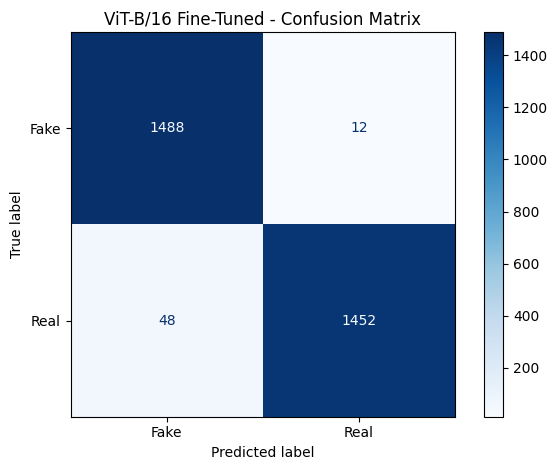

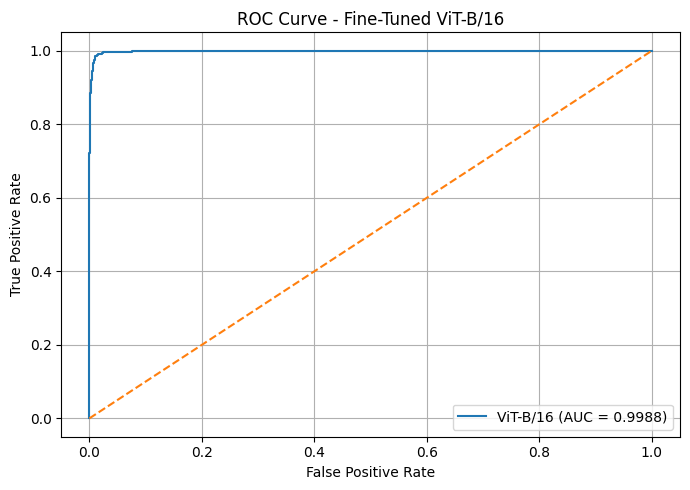

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

# 1. Confusion Matrix
plt.figure(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=["Fake", "Real"],
    cmap="Blues"
)

plt.title("ViT-B/16 Fine-Tuned - Confusion Matrix")
plt.tight_layout()
plt.savefig("vit_confusion_matrix.png", dpi=300)
plt.show()


# 2. ROC Curve
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ViT-B/16 (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Fine-Tuned ViT-B/16")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("vit_roc_curve.png", dpi=300)
plt.show()

In [ ]:
files.download("vit_confusion_matrix.png")
files.download("vit_roc_curve.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install -q datasets pillow

from datasets import load_dataset

dataset = load_dataset("prithivMLmods/OpenDeepfake-Preview")

print(dataset)
print("Dataset splits:", dataset.keys())
print("Available columns:", dataset["train"].column_names)
print("Number of images:", len(dataset["train"]))

README.md:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

dataset/OpenDeepfake-Preview (1).parquet: reconstructing file:   0%|          |  0.00B /  504MB            

dataset/OpenDeepfake-Preview (1).parquet: downloading bytes:           |  0.00B            

dataset/OpenDeepfake-Preview (10).parque(…): reconstructing file:   0%|          |  0.00B /  137MB            

dataset/OpenDeepfake-Preview (10).parque(…): downloading bytes:           |  0.00B            

dataset/OpenDeepfake-Preview (2).parquet: reconstructing file:   0%|          |  0.00B /  522MB            

... (13 outputs left out)

dataset/OpenDeepfake-Preview (9).parquet: reconstructing file:   0%|          |  0.00B /  512MB            

dataset/OpenDeepfake-Preview (9).parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/19999 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 19999
    })
})
Dataset splits: dict_keys(['train'])
Available columns: ['image', 'label']
Number of images: 19999


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

# Extract labels
labels = np.array(dataset["train"]["label"])
indices = np.arange(len(labels))

# First split: 70% training, 30% remaining
train_idx, remaining_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second split: divide remaining 30% equally
val_idx, test_idx = train_test_split(
    remaining_idx,
    test_size=0.50,
    random_state=42,
    stratify=labels[remaining_idx]
)

# Create datasets
train_ds = dataset["train"].select(train_idx.tolist())
val_ds = dataset["train"].select(val_idx.tolist())
test_ds = dataset["train"].select(test_idx.tolist())

print("TRAIN:", len(train_ds))
print("VALIDATION:", len(val_ds))
print("TEST:", len(test_ds))

print("\nClass distribution:")
for name, ds in [
    ("Train", train_ds),
    ("Validation", val_ds),
    ("Test", test_ds)
]:
    print(name, np.bincount(ds["label"], minlength=2))

TRAIN: 13999
VALIDATION: 3000
TEST: 3000

Class distribution:
Train [7000 6999]
Validation [1500 1500]
Test [1500 1500]


In [ ]:
import hashlib
from collections import defaultdict

def image_hash(image):
    image = image.convert("RGB")
    image_bytes = (
        str(image.size).encode() + image.tobytes()
    )
    return hashlib.sha256(image_bytes).hexdigest()


split_datasets = {
    "train": train_ds,
    "validation": val_ds,
    "test": test_ds
}

hash_locations = defaultdict(list)

for split_name, ds in split_datasets.items():

    print("Checking:", split_name)

    for idx, sample in enumerate(ds):
        h = image_hash(sample["image"])
        hash_locations[h].append((split_name, idx))

# Find hashes appearing in multiple splits
cross_split_duplicates = {
    h: locations
    for h, locations in hash_locations.items()
    if len(set(split for split, _ in locations)) > 1
}

print("\nDUPLICATE CHECK RESULTS")
print("------------------------")
print("Total images checked:", sum(map(len, split_datasets.values())))
print("Unique image hashes:", len(hash_locations))
print("Cross-split duplicate groups:", len(cross_split_duplicates))

for h, locations in list(cross_split_duplicates.items())[:10]:
    print(h[:12], locations)

Checking: train
Checking: validation
Checking: test

DUPLICATE CHECK RESULTS
------------------------
Total images checked: 19999
Unique image hashes: 19947
Cross-split duplicate groups: 22
f0e58babd72a [('train', 567), ('validation', 1206)]
6211a684ccc2 [('train', 919), ('test', 2280)]
6fd18662f4a2 [('train', 2500), ('validation', 1169)]
510b6690e857 [('train', 2788), ('validation', 1648)]
dd303fa7866e [('train', 2962), ('validation', 555)]
971f3f5f2d9b [('train', 4219), ('test', 1949)]
79d76813b41d [('train', 5023), ('train', 7382), ('train', 9678), ('validation', 957), ('test', 1540)]
5da75189e784 [('train', 5171), ('validation', 2096)]
92190d5a8bc8 [('train', 5339), ('validation', 1670)]
054c11d85639 [('train', 8086), ('test', 1282)]


In [ ]:
# Inspect every cross-split duplicate group

print("TOTAL CROSS-SPLIT DUPLICATE GROUPS:",
      len(cross_split_duplicates))

for i, (h, locations) in enumerate(
    cross_split_duplicates.items(), 1
):
    print(f"\nDuplicate group {i}")

    for split_name, idx in locations:
        ds = split_datasets[split_name]
        label = ds[int(idx)]["label"]

        print(
            f"Split: {split_name}, "
            f"Index: {idx}, "
            f"Label: {label}"
        )

TOTAL CROSS-SPLIT DUPLICATE GROUPS: 22

Duplicate group 1
Split: train, Index: 567, Label: 0
Split: validation, Index: 1206, Label: 0

Duplicate group 2
Split: train, Index: 919, Label: 0
Split: test, Index: 2280, Label: 0

Duplicate group 3
Split: train, Index: 2500, Label: 0
Split: validation, Index: 1169, Label: 0

Duplicate group 4
Split: train, Index: 2788, Label: 0
Split: validation, Index: 1648, Label: 0

Duplicate group 5
Split: train, Index: 2962, Label: 0
Split: validation, Index: 555, Label: 0

Duplicate group 6
Split: train, Index: 4219, Label: 0
Split: test, Index: 1949, Label: 0

Duplicate group 7
Split: train, Index: 5023, Label: 0
Split: train, Index: 7382, Label: 0
Split: train, Index: 9678, Label: 0
Split: validation, Index: 957, Label: 0
Split: test, Index: 1540, Label: 0

Duplicate group 8
Split: train, Index: 5171, Label: 0
Split: validation, Index: 2096, Label: 0

Duplicate group 9
Split: train, Index: 5339, Label: 0
Split: validation, Index: 1670, Label: 0

Dupli

In [ ]:
import hashlib
import numpy as np

original_ds = dataset["train"]

seen_hashes = {}
unique_indices = []
conflicting_labels = []

for idx, sample in enumerate(original_ds):

    image = sample["image"].convert("RGB")

    image_bytes = str(image.size).encode() + image.tobytes()

    h = hashlib.sha256(image_bytes).hexdigest()

    label = sample["label"]

    if h not in seen_hashes:
        seen_hashes[h] = (idx, label)
        unique_indices.append(idx)

    else:
        original_idx, original_label = seen_hashes[h]

        if label != original_label:
            conflicting_labels.append(
                (original_idx, idx, original_label, label)
            )

# Create deduplicated dataset
clean_ds = original_ds.select(unique_indices)

print("Original images:", len(original_ds))
print("Unique images:", len(clean_ds))
print("Removed duplicates:", len(original_ds) - len(clean_ds))
print("Conflicting-label groups:", len(conflicting_labels))
print("Class distribution:", np.bincount(clean_ds["label"]))

Original images: 19999
Unique images: 19947
Removed duplicates: 52
Conflicting-label groups: 0
Class distribution: [9948 9999]


In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

labels = np.array(clean_ds["label"])
indices = np.arange(len(clean_ds))

# 70% training, 30% remaining
train_idx, remaining_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Split remaining data equally
val_idx, test_idx = train_test_split(
    remaining_idx,
    test_size=0.50,
    random_state=42,
    stratify=labels[remaining_idx]
)

train_ds = clean_ds.select(train_idx.tolist())
val_ds = clean_ds.select(val_idx.tolist())
test_ds = clean_ds.select(test_idx.tolist())

print("CLEAN DATASET SPLITS")
print("--------------------")

for name, ds in [
    ("Train", train_ds),
    ("Validation", val_ds),
    ("Test", test_ds)
]:
    print(
        name,
        "Images:", len(ds),
        "Class distribution:",
        np.bincount(ds["label"], minlength=2)
    )

print("Total:", len(train_ds) + len(val_ds) + len(test_ds))

CLEAN DATASET SPLITS
--------------------
Train Images: 13962 Class distribution: [6963 6999]
Validation Images: 2992 Class distribution: [1492 1500]
Test Images: 2993 Class distribution: [1493 1500]
Total: 19947


In [ ]:
from collections import defaultdict
import hashlib

split_datasets = {
    "train": train_ds,
    "validation": val_ds,
    "test": test_ds
}

hash_locations = defaultdict(list)

for split_name, ds in split_datasets.items():

    print("Checking:", split_name)

    for idx, sample in enumerate(ds):

        image = sample["image"].convert("RGB")

        image_bytes = str(image.size).encode() + image.tobytes()

        h = hashlib.sha256(image_bytes).hexdigest()

        hash_locations[h].append(split_name)

cross_split_duplicates = {
    h: splits
    for h, splits in hash_locations.items()
    if len(set(splits)) > 1
}

print("\nFINAL DUPLICATE VERIFICATION")
print("Total images:", sum(len(ds) for ds in split_datasets.values()))
print("Unique hashes:", len(hash_locations))
print("Cross-split duplicate groups:", len(cross_split_duplicates))

assert len(cross_split_duplicates) == 0, "Duplicates detected!"
print("SUCCESS: No exact duplicates across splits.")

Checking: train
Checking: validation
Checking: test

FINAL DUPLICATE VERIFICATION
Total images: 19947
Unique hashes: 19947
Cross-split duplicate groups: 0
SUCCESS: No exact duplicates across splits.


In [16]:
import os, shutil, json
from google.colab import files
from flax import serialization
from sklearn.metrics import roc_auc_score

up = files.upload()
shutil.move(list(up.keys())[0], f"{CHECKPOINT_DIR}/best_vit_checkpoint.msgpack")

with open(f"{CHECKPOINT_DIR}/best_vit_checkpoint.msgpack", "rb") as f:
    ft_params = serialization.from_bytes(variables["params"], f.read())
ft_params = jax.tree_util.tree_map(jnp.asarray, ft_params)
opt_state = optimizer.init(ft_params)

history = {"train_loss": [0.2178], "train_accuracy": [0.9269],
           "val_loss": [0.0555], "val_accuracy": [0.9800]}

def get_preds(params, ds, bs=16):
    yt, yp, ys = [], [], []
    for x, y in create_batches(ds, batch_size=bs):
        pr = jax.nn.softmax(model.apply({"params": params}, jnp.asarray(x), train=False), -1)
        yt += y.tolist(); yp += np.asarray(jnp.argmax(pr, -1)).tolist(); ys += np.asarray(pr[:, 1]).tolist()
    return np.array(yt), np.array(yp), np.array(ys)

y_true, y_pred, y_scores = get_preds(ft_params, test_ds)
np.savez("/content/epoch1_predictions.npz", y_true=y_true, y_pred=y_pred, y_scores=y_scores)
print(len(train_ds), len(val_ds), len(test_ds))
print("Test acc:", (y_true == y_pred).mean(), "| AUC:", roc_auc_score(y_true, y_scores), "| errors:", (y_true != y_pred).sum())

Saving best_vit_checkpoint.msgpack to best_vit_checkpoint.msgpack
13999 3000 3000
Test acc: 0.98 | AUC: 0.9988302222222223 | errors: 60


In [17]:
import time
os.system(f"cp {CHECKPOINT_DIR}/best_vit_checkpoint.msgpack {CHECKPOINT_DIR}/vit_epoch1.msgpack")

@jax.jit
def eval_step(params, images, labels):
    logits = model.apply({"params": params}, images, train=False)
    loss = optax.softmax_cross_entropy_with_integer_labels(logits, labels).sum()
    return loss, (jnp.argmax(logits, -1) == labels).sum()

def fast_eval(params, ds, bs=16):
    L = C = N = 0
    for x, y in create_batches(ds, batch_size=bs):
        l, c = eval_step(params, jnp.asarray(x), jnp.asarray(y))
        L += float(l); C += int(c); N += len(y)
    return L / N, C / N

np.random.seed(42)
EXTRA_EPOCHS = 2
best_val_loss, best_params, best_epoch = history["val_loss"][-1], ft_params, 1

for epoch in range(2, 2 + EXTRA_EPOCHS):
    t0 = time.time(); tl = tc = tn = 0
    for images, labels in create_batches(train_ds, batch_size=FT_BATCH_SIZE, shuffle=True):
        ft_params, opt_state, loss, acc = train_step(
            ft_params, opt_state, jnp.asarray(images), jnp.asarray(labels))
        n = len(labels); tl += float(loss) * n; tc += float(acc) * n; tn += n
    vl, va = fast_eval(ft_params, val_ds)
    for k, v in zip(["train_loss", "train_accuracy", "val_loss", "val_accuracy"],
                    [tl / tn, tc / tn, vl, va]):
        history[k].append(v)
    print(f"Epoch {epoch}: train loss {tl/tn:.4f} acc {tc/tn:.4f} | "
          f"val loss {vl:.4f} acc {va:.4f} | {(time.time()-t0)/60:.1f} min")
    with open(f"{CHECKPOINT_DIR}/vit_epoch{epoch}.msgpack", "wb") as f:
        f.write(serialization.to_bytes(ft_params))
    if vl < best_val_loss:
        best_val_loss, best_params, best_epoch = vl, ft_params, epoch

print("Best epoch by validation loss:", best_epoch)
json.dump(history, open("/content/training_history.json", "w"), indent=2)

Epoch 2: train loss 0.0356 acc 0.9888 | val loss 0.0748 acc 0.9740 | 18.0 min
Epoch 3: train loss 0.0212 acc 0.9926 | val loss 0.0634 acc 0.9817 | 17.3 min
Best epoch by validation loss: 1


In [18]:
y_true, y_pred, y_scores = get_preds(best_params, test_ds)
print("Best epoch:", best_epoch)
print("Final test acc:", (y_true == y_pred).mean(), "| AUC:", roc_auc_score(y_true, y_scores), "| errors:", (y_true != y_pred).sum())
np.savez("/content/final_predictions.npz", y_true=y_true, y_pred=y_pred, y_scores=y_scores)

Best epoch: 1
Final test acc: 0.98 | AUC: 0.9988302222222223 | errors: 60


Epoch 1 (selected): acc 0.9800 | AUC 0.9988 | errors 60
Epoch 2: acc 0.9677 | AUC 0.9987 | errors 97
Epoch 3: acc 0.9780 | AUC 0.9992 | errors 66


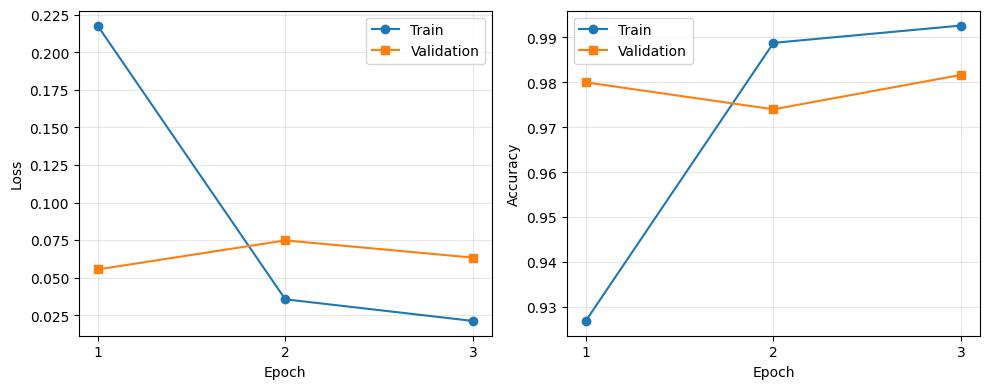

In [19]:
import matplotlib.pyplot as plt

# Epoch 3 (current ft_params) and epoch 2 (from saved file) on the test set
with open(f"{CHECKPOINT_DIR}/vit_epoch2.msgpack", "rb") as f:
    params_ep2 = jax.tree_util.tree_map(jnp.asarray, serialization.from_bytes(variables["params"], f.read()))

for name, p in [("Epoch 1 (selected)", best_params), ("Epoch 2", params_ep2), ("Epoch 3", ft_params)]:
    yt, yp, ys = get_preds(p, test_ds)
    print(f"{name}: acc {(yt==yp).mean():.4f} | AUC {roc_auc_score(yt, ys):.4f} | errors {(yt!=yp).sum()}")

# Learning curves
ep = [1, 2, 3]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ep, history["train_loss"], "o-", label="Train"); ax[0].plot(ep, history["val_loss"], "s-", label="Validation")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].set_xticks(ep); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ep, history["train_accuracy"], "o-", label="Train"); ax[1].plot(ep, history["val_accuracy"], "s-", label="Validation")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].set_xticks(ep); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("vit_learning_curves.png", dpi=300); plt.show()

In [29]:
!pip install -q datasets scikit-learn pandas numpy pillow matplotlib

In [30]:
from datasets import load_dataset

dataset = load_dataset(
    "prithivMLmods/OpenDeepfake-Preview",
    split="train"
)

print("Dataset loaded:", len(dataset))
print(dataset.features)

Dataset loaded: 19999
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['fake', 'real'])}


In [31]:
import hashlib
from collections import Counter

hashes = []

for item in dataset:
    image = item["image"].convert("RGB")
    hashes.append(
        hashlib.sha256(image.tobytes()).hexdigest()
    )

seen = set()
keep_indices = []

for i, h in enumerate(hashes):
    if h not in seen:
        seen.add(h)
        keep_indices.append(i)

clean_dataset = dataset.select(keep_indices)

print("Original images:", len(dataset))
print("Clean images:", len(clean_dataset))
print("Duplicates removed:", len(dataset) - len(clean_dataset))

Original images: 19999
Clean images: 19947
Duplicates removed: 52
